<a href="https://colab.research.google.com/github/soleildayana/Modern-Astrophysics/blob/main/ISM_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Segundo Proyecto Computacional - Astrofísica Moderna
Astronomía UdeA

**Soleil Dayana Niño Murcia**

# **Un modelo mínimo del medio interestelar galáctico de los $\mu$ m a los kpc**

En este problema vamos a construir un modelo num ́erico de la radiaci ́on en el medio interestelar (ISM)
desde primeros principios. La idea es analizar el presupuesto energ ́etico de la radiaci ́on en la V ́ıa L ́actea
desde el UV emitido por estrellas masivas hasta el IR reemitido por el polvo interestelar. A pesar de la
diferencia de escalas (desde granos submicrom ́etricos hasta el radio gal ́actico) veremos c ́omo podemos

usar aproximaciones de orden de magnitud para reproducir observaciones como el flujo del campo in-
terestelar de radiaci ́on (ISRF), la temperatura del polvo en nubes moleculares, la intensidad infrarroja

difusa y tambi ́en la curva de extinci ́on y la proporci ́on fiducial.

In [1]:
# Librerías

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

#recordar eliminar lo que no se usó en la revisión final

rng = np.random.default_rng(42) # Semilla fija

In [2]:
# Constantes en cgs
#(en la revisión final evaluar si se pueden reemplazar con librerías como astropy)

kpc = 3.086e21 # cm
sigma_sb = 5.67e-5 # cm^2 g^-1 K^-4
k_b = 1.38e-16 # erg/K
h = 6.626e-27 # erg s
c = 2.9979e10 # cm/s
b_wien =0.2898 # cm K

## a. Distribución en el disco
La mayorıa de la radiacion interestelar proviene de luz emitida por las estrellas m ́as masivas (tipo O). El numero aproximado de estas estrellas en la Vıa Lactea es $N_O* ≈ 5 * 104$, y su luminosidad individual es aproximadamente $LO* ≈ 1040 erg s−1$. Simule la distribucion de estas estrellas en la
Vıa Lactea como si estuvieran todas localizadas sobre un disco y distribuidas de manera aleatoria (uniforme) a lo largo y ancho de un área circular con radio $r_{gal}$. Haga una grafica 2D que muestre la
distribución de las estrellas como puntos aleatoriamente distribuidos en un disco de radio $r_{gal}$ (tome $r_{gal}$ ≈ 36 kpc).

Una celda de constantes en cgs: kpc = 3.086e21 cm, σ_SB, k_B, h, c, b de Wien (0.2898 cm·K). Trabaja todo en cgs y convierte a kpc solo para graficar.
Semilla fija (np.random.default_rng(seed)) para que sea reproducible.
Funciones reutilizables desde el principio: generar_galaxia(), flujo(r_punto, estrellas, a_ext=0), T_equilibrio(F), Q_mie(a, lam).
Deja listo el espacio para la declaración de uso ético de IA, porque es requisito de entrega.

Distribución en el disco. Para muestrear uniforme en área usa r = R·√U, no r = R·U; el segundo es el error clásico y acumula estrellas en el centro. El ángulo es θ = 2πU. Grafica las estrellas junto con los puntos de medición, de 0 a 36 kpc cada 2 kpc sobre y = 0.

In [3]:
def generar_galaxia(N, r_gal):
    """
    Genera posiciones (x, y) de N estrellas distribuidas uniformemente
    en un disco bidimensional de radio r_gal.
    """
    u = rng.random(int(N))
    theta = rng.random(int(N)) * 2 * np.pi
    r = r_gal * np.sqrt(u)

    x = r * np.cos(theta)
    y = r * np.sin(theta)
    return x, y

In [4]:
N_O, L_O = 5e4, 1e40 # Número y luminosidad de estrellas de tipo O
r_gal_kpc = 36.0

# Generar coordenadas de las estrellas (en kpc para graficar)
x_estrellas, y_estrellas = generar_galaxia(N_O, r_gal_kpc)

# Puntos de medición: de 0 a 36 kpc cada 2 kpc sobre y = 0
x_med = np.arange(0, 36.1, 2.0)
y_med = np.zeros_like(x_med)

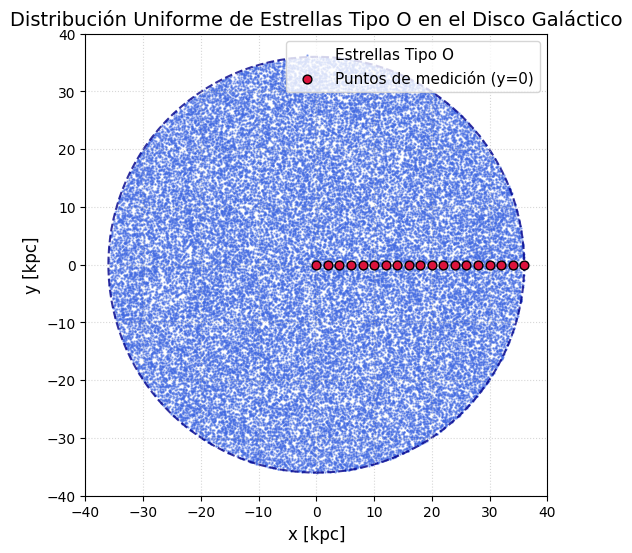

In [25]:
plt.figure(figsize=(10, 6))

# Graficar la distribución
plt.scatter(x_estrellas, y_estrellas, s=0.5, color='royalblue', alpha=0.5, label='Estrellas Tipo O')
plt.scatter(x_med, y_med, color='crimson', s=40, edgecolor='black', zorder=5, label='Puntos de medición (y=0)')

# Dibujar el borde del disco galáctico
anillo = plt.Circle((0, 0), r_gal_kpc, color='darkblue', fill=False, linestyle='--', linewidth=1.5, alpha=0.8)
plt.gca().add_patch(anillo)

plt.title('Distribución Uniforme de Estrellas Tipo O en el Disco Galáctico', fontsize=14)
plt.xlabel('x [kpc]', fontsize=12)
plt.ylabel('y [kpc]', fontsize=12)
plt.xlim(-40, 40)
plt.ylim(-40, 40)
plt.gca().set_aspect('equal', adjustable='box')
plt.grid(True, linestyle=':', alpha=0.5)
plt.legend(loc='upper right', fontsize=11)
plt.show()

$F_{ISM}(r) = \sum_i \frac{L_{O*}}{4\pi d_i^2}$



## b. Flujo sin extinción
Usando la distribuci ́on estelar generada en a, calcule el flujo F_ISM (en erg s−1 cm−2) de todas las estrellas tipo O sobre cada uno de los puntos ubicados entre el centro de la V ́ıa L ́actea (r = 0) y el borde (r = 36 kpc) a intervalos de 2 kpc. Para evitar el efecto que tendr ́ıa el estar anormalmente cerca a una estrella O, es necesario correr varias simulaciones distintas y tomar el m ́ınimo valor de flujo entre todas las simulaciones para cada r.

### Formulación Analítica con Corte Físico
Analíticamente, podemos modelar el disco de estrellas con una densidad superficial de número constante $\Sigma = \frac{N_O}{\pi r_{gal}^2}$. El flujo total en un punto a distancia $r$ del centro se puede aproximar mediante la integral:

$$F_{\text{analítico}}(r) = \int_{Disco} \frac{L_O}{4\pi d^2} \Sigma dA$$

Donde $d$ es la distancia desde el diferencial de área a nuestro punto de observación. Para resolver numéricamente la divergencia logarítmica cuando $d \to 0$, introducimos un radio de corte físico inferior $d_{\text{min}}$ equivalente a la separación media típica entre estrellas en el plano: $d_{\text{min}} \approx \frac{1}{\sqrt{\Sigma}}$.

In [6]:
def flujo(r_punto, estrellas, a_ext=0):
    """
    Calcula el flujo recibido en un punto de observación r_punto=(x_p, y_p) [en kpc]
    proveniente de todas las estrellas [en kpc]. El resultado está en erg s^-1 cm^-2.
    """
    x_p, y_p = r_punto
    x_e, y_e = estrellas

    # Distancia en kpc de cada estrella al punto de medición
    d_kpc = np.sqrt((x_e - x_p)**2 + (y_e - y_p)**2)

    # Evitamos la división exacta por cero si una estrella coincide con el punto de observación
    d_kpc = np.where(d_kpc == 0, 1e-10, d_kpc)

    # Convertir distancias a cm para el cálculo físico
    d_cm = d_kpc * kpc

    # Ley del inverso del cuadrado (sin extinción, a_ext = 0 por ahora)
    # Si hubiera extinción, aplicaríamos el factor 10**(-0.4 * a_ext * d_kpc)
    flujos_individuales = L_O / (4 * np.pi * d_cm**2)
    if a_ext > 0:
        flujos_individuales *= 10**(-0.4 * a_ext * d_kpc)

    return np.sum(flujos_individuales)

In [7]:
import scipy.integrate as integrate

# --- 1. Generación de Realizaciones de Galaxias Únicas ---
num_simulaciones = 300
galaxias_simuladas = [generar_galaxia(N_O, r_gal_kpc) for _ in range(num_simulaciones)]

# --- 2. Simulación Monte Carlo Sin Extinción ---
flujos_simulaciones = []
for estrellas_sim in galaxias_simuladas:
    flujos_r = [flujo((r_p, 0.0), estrellas_sim) for r_p in x_med]
    flujos_simulaciones.append(flujos_r)

# Convertir a arreglo numpy y tomar el mínimo por cada radiolujos_simulaciones = np.array(flujos_simulaciones)
F_ISM_min = np.min(flujos_simulaciones, axis=0)

# --- 3. Solución Analítica con Corte Físico ---
Sigma = N_O / (np.pi * r_gal_kpc**2)        # Densidad superficial en kpc^-2
d_min_kpc = 1.0 / np.sqrt(Sigma)             # Separación media en kpc (corte de divergencia)

def integrand(theta, r_prime, r_obs):
    d2 = r_obs**2 + r_prime**2 - 2 * r_obs * r_prime * np.cos(theta)
    d2_safe = np.maximum(d2, d_min_kpc**2)
    d2_cm2 = d2_safe * (kpc**2)
    return (L_O / (4 * np.pi * d2_cm2)) * (Sigma) * r_prime

F_analitico = []
for r_obs in x_med:
    val, _ = integrate.dblquad(
        integrand,
        0, r_gal_kpc,
        lambda r_p: 0,
        lambda r_p: 2 * np.pi,
        args=(r_obs,)
    )
    F_analitico.append(val)

F_analitico = np.array(F_analitico)

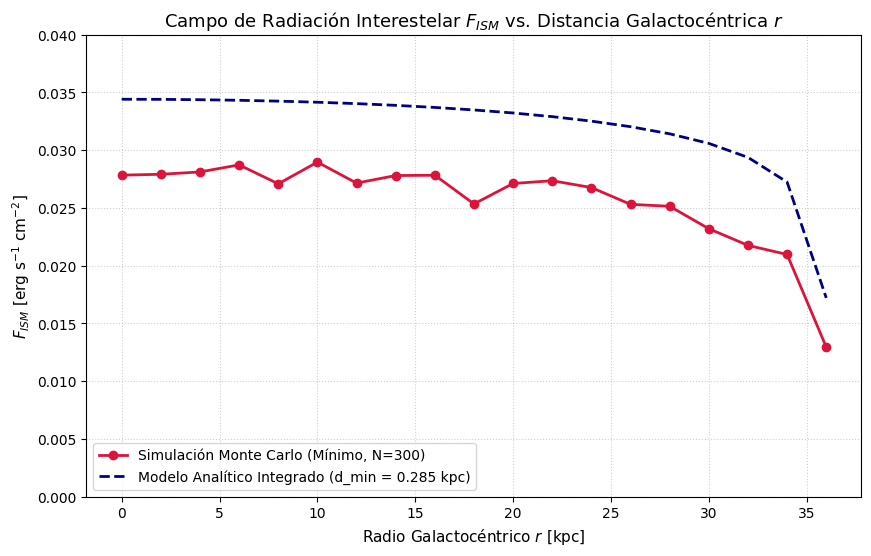

In [8]:
# --- 3. Gráfica Comparativa ---
plt.figure(figsize=(10, 6))

# Graficar simulación Monte Carlo
plt.plot(x_med, F_ISM_min, 'o-', color='crimson',
         label=f'Simulación Monte Carlo (Mínimo, N={num_simulaciones})', linewidth=2)

# Graficar modelo analítico indicando el valor de d_min utilizado en el corte
plt.plot(x_med, F_analitico, '--', color='navy',
         label=f'Modelo Analítico Integrado (d_min = {d_min_kpc:.3f} kpc)', linewidth=2)

# Cambiado a escala lineal para mejor visualización del rango de factor ~2
plt.yscale('linear')
plt.ylim(0, 0.04)  # Ajuste de límites para ver claramente el comportamiento y el cero

plt.title('Campo de Radiación Interestelar $F_{ISM}$ vs. Distancia Galactocéntrica $r$', fontsize=13)
plt.xlabel('Radio Galactocéntrico $r$ [kpc]', fontsize=11)
plt.ylabel('$F_{ISM}$ [erg s$^{-1}$ cm$^{-2}$]', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=10, loc='lower left')
plt.show()

## c. Flujo **con** extinción
Considerando un coeficiente de extinción $a_λ$ = 3.5 mag kpc⁻1 ($τ_λ = 1.086 $a_λ$  L).

In [9]:
a_lambda = 3.5
tau_lambda = 1.086 * a_lambda

# --- 4. Simulación Monte Carlo Con Extinción (Usando las MISMAS realizaciones) ---
flujos_extintos = []
for estrellas_sim in galaxias_simuladas:
    flujos_r = [flujo((r_p, 0.0), estrellas_sim, a_ext=a_lambda) for r_p in x_med]
    flujos_extintos.append(flujos_r)

flujos_extintos = np.array(flujos_extintos)
F_ISM_extintos = np.min(flujos_extintos, axis=0)

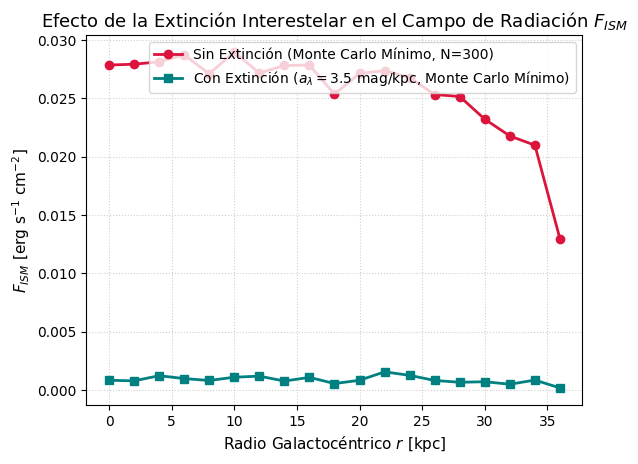

In [10]:
# --- Gráfica Comparativa de Flujos Con vs Sin Extinción ---
# Flujo sin extinción (Monte Carlo mínimo)
plt.plot(x_med, F_ISM_min, 'o-', color='crimson',
         label=f'Sin Extinción (Monte Carlo Mínimo, N={num_simulaciones})', linewidth=2)

# Flujo con extinción (Monte Carlo mínimo)
plt.plot(x_med, F_ISM_extintos, 's-', color='teal',
         label=f'Con Extinción ($a_\\lambda = {a_lambda}$ mag/kpc, Monte Carlo Mínimo)', linewidth=2)

# Escala lineal y etiquetas claras
plt.yscale('linear')
plt.title('Efecto de la Extinción Interestelar en el Campo de Radiación $F_{ISM}$', fontsize=13)
plt.xlabel('Radio Galactocéntrico $r$ [kpc]', fontsize=11)
plt.ylabel('$F_{ISM}$ [erg s$^{-1}$ cm$^{-2}$]', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=10, loc='upper right')
plt.show()

## d. Fotones

Teniendo en cuenta que la temperatura de estas estrellas es TO* ≈ 4 × 104 K, calcule la energ ́ıa
promedio de los fotones (⟨E⟩ ≈ 2.7kBT) y su longitud de onda correspondiente, λO* y el n ́umero
de fotones por unidad de  ́area por unidad de tiempo (flujo de fotones), generando una gr ́afica similar
a las anteriores. Compare con el valor medido en el medio interestelara
(10^8
fotones cm−2
s
−1
).

In [11]:
# Constantes (cgs)
T_O = 4e4 # K
Phi_obs = 1e8   # valor medido en el ISM

# Energía promedio del fotón y longitud de onda correspondiente
E_prom = 2.7 * k_b * T_O # erg
lam_O = h * c / E_prom  # cm

print(f"<E> = {E_prom:.3e} erg = {E_prom/1.602e-12:.2f} eV")
print(f"lambda_O* = {lam_O:.3e} cm = {lam_O*1e7:.1f} nm")

<E> = 1.490e-11 erg = 9.30 eV
lambda_O* = 1.333e-05 cm = 133.3 nm


In [12]:
# Flujo de fotones (fotones cm^-2 s^-1)
# F_b: flujo mínimo sin extinción (punto b); F_c: con extinción (punto c)
Phi_b = F_ISM_min / E_prom
Phi_c = F_ISM_extintos / E_prom
print(f"Phi(b) = {Phi_b[0]:.2e}  ->  Phi/Phi_obs = {Phi_b[0]/Phi_obs:.1f}")
print(f"Phi(c) = {Phi_c[0]:.2e}  ->  Phi/Phi_obs = {Phi_c[0]/Phi_obs:.1f}")

Phi(b) = 1.87e+09  ->  Phi/Phi_obs = 18.7
Phi(c) = 5.51e+07  ->  Phi/Phi_obs = 0.6


In [30]:
Phi_b[0]/Phi_c[0]

np.float64(33.88619339085833)

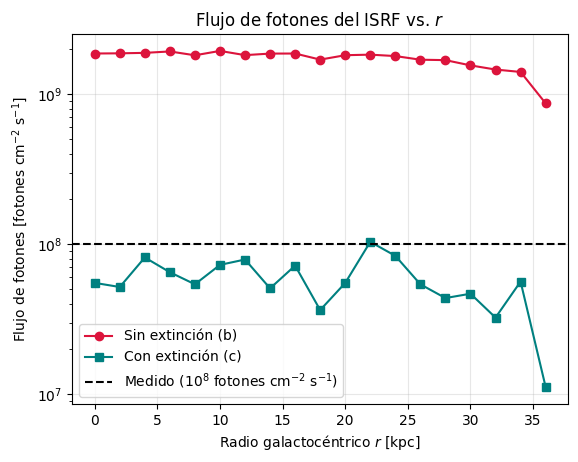

In [13]:
# Gráfica

plt.plot(x_med, Phi_b, 'o-', color='crimson', label='Sin extinción (b)')
plt.plot(x_med, Phi_c, 's-', color='teal', label='Con extinción (c)')
plt.axhline(Phi_obs, color='k', ls='--', label=r'Medido ($10^8$ fotones cm$^{-2}$ s$^{-1}$)')
plt.yscale('log')
plt.xlabel('Radio galactocéntrico $r$ [kpc]')
plt.ylabel(r'Flujo de fotones [fotones cm$^{-2}$ s$^{-1}$]')
plt.title('Flujo de fotones del ISRF vs. $r$')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## e. Temperatura del polvo

El flujo FISM del campo interestelar de radiaci ́on calienta los granos de polvo en el medio interestelar hasta cierta temperatura de equilibrio Tg. En promedio estos granos tienen un tamaño a ≈ 0.1 μm. Si cada grano de polvo fuera un cuerpo negro, reemitir ́ıa la radiaci ́on absorbida con un pico de emisión en λg = λWien(Tg) seg ́un la Ley de Stefan-Boltzmann (FSB = σT4
g). Dado que esta radiaci ́on es infraroja (λg > 2πa) se cumple que Qλg ≈ (2πa/λg) β (teor ́ıa de Mie). Esto significa que el flujo emitido por el polvo no es exactamente el de un cuerpo negro sino que ser ́a modulado por Qλ, de manera que Fem ≈ FSBQλ. Suponiendo que los granos de polvo emiten toda la radiaci ́on absorbida (Fem = Fabs = FISM), y tomando un valor de β = 1.45 encuentre la temperatura de equilibrio Tg para los granos de polvo en el medio interestelar para cada uno de los valores de FISM del punto c, y haga una gr ́afica de Tg vs. r con los resultados.

Toda la energía absorbida por el grano de polvo procedente del campo de radiación interestelar ($F_{\text{abs}} = F_{\text{ISM}}$) debe ser reemitida en el infrarrojo ($F_{\text{em}}$).

**Flujo emitido por el polvo:**
Un cuerpo negro perfecto emitiría $F_{\text{SB}} = \sigma T_g^4$. Sin embargo, los granos de polvo son pequeños ($a \approx 0.1\ \mu\text{m}$) comparados con la longitud de onda infrarroja a la que emiten ($\lambda_g > 2\pi a$), por lo que emiten de forma ineficiente como un cuerpo gris: $$F_{\text{em}} = F_{\text{SB}} \cdot Q_{\lambda_g} = \sigma T_g^4 \cdot \left(\frac{2\pi a}{\lambda_g}\right)^\beta$$

**Ley de Wien**: La longitud de onda característica de emisión del polvo depende de su temperatura según Wien: $$\lambda_g = \frac{b_W}{T_g} \quad \text{donde } b_W \approx 0.289777\text{ cm}\cdot\text{K} \quad (2897.77\ \mu\text{m}\cdot\text{K})$$
Sustitución de $\lambda_g$ en $Q_{\lambda_g}$: $$Q_{\lambda_g} = \left(\frac{2\pi a \cdot T_g}{b_W}\right)^\beta = \left(\frac{2\pi a}{b_W}\right)^\beta T_g^\beta$$Balance Térmico $F_{\text{em}} = F_{\text{ISM}}(r)$: $$\sigma T_g^4 \cdot \left(\frac{2\pi a}{b_W}\right)^\beta T_g^\beta = F_{\text{ISM}}(r) \implies \sigma \left(\frac{2\pi a}{b_W}\right)^\beta T_g^{4 + \beta} = F_{\text{ISM}}(r)$$

$\sigma \left(\frac{2\pi a}{b}\right)^{\beta} T^{4+\beta} = F_{ISM}
\quad\Rightarrow\quad
T_g = \left[\frac{F_{ISM}}{\sigma\,(2\pi a/b)^{\beta}}\right]^{1/(4+\beta)}$

In [14]:
# Constantes
beta = 1.45
a_cm = 1e-4

In [15]:
def temperatura_polvo(a_cm, beta):
    factor_mie = (2 * np.pi * a_cm / b_wien)**beta
    # Calculamos T_g correctamente usando F_ISM con extinción (F_ISM_extintos)
    T_g = F_ISM_extintos / (sigma_sb * factor_mie)
    T_g = T_g**(1 / (4 + beta))
    return T_g

In [16]:
# Recalcular T_g con la función corregida
T_g = temperatura_polvo(a_cm, beta)
print("Temperaturas calculadas para cada radio (K):")
T_g

Temperaturas calculadas para cada radio (K):


array([8.35214238, 8.25573717, 8.97208912, 8.60683307, 8.31893401,
       8.78700477, 8.92079956, 8.22436467, 8.76854927, 7.73648739,
       8.35067049, 9.3769886 , 9.0137953 , 8.31872282, 8.00258118,
       8.10111715, 7.57390931, 8.38276956, 6.2297254 ])

In [17]:
Tg_mean = np.mean(T_g)
print(f"Temperatura de equilibrio Tg promedio: {Tg_mean:.3f} K")

Temperatura de equilibrio Tg promedio: 8.331 K


2*pi*a = 6.283e-04 cm
lambda_g promedio = 3.504e-02 cm
¿Se cumple lambda_g > 2*pi*a en todos los puntos?: True


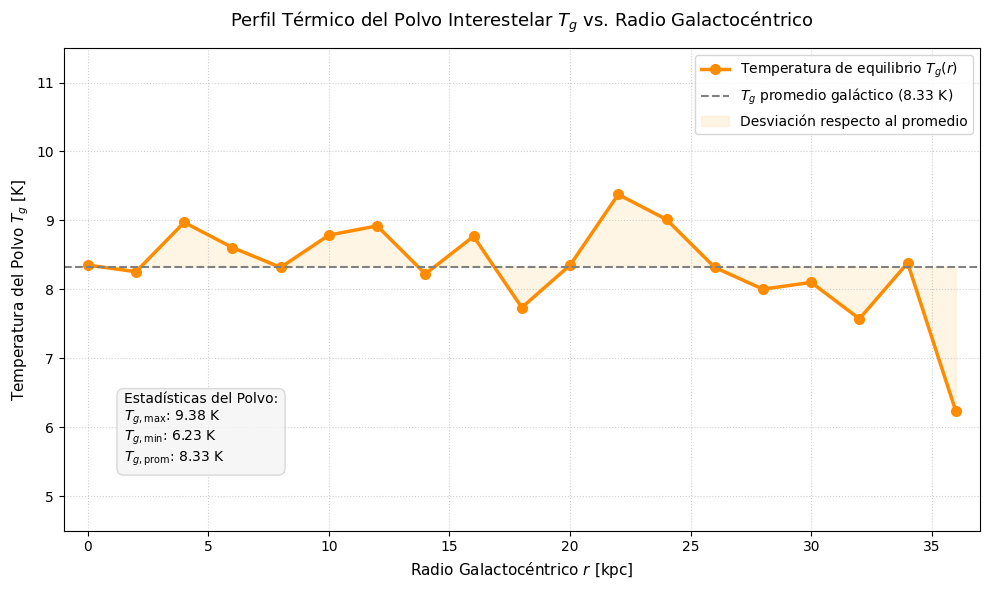

In [27]:
# Comprobar la aproximación de Mie: λ_g > 2πa
pi2a = 2 * np.pi * a_cm
lambda_g = b_wien / T_g

print(f"2*pi*a = {pi2a:.3e} cm")
print(f"lambda_g promedio = {np.mean(lambda_g):.3e} cm")
print(f"¿Se cumple lambda_g > 2*pi*a en todos los puntos?: {np.all(lambda_g > pi2a)}")

# Graficar la Temperatura del Polvo vs. Radio Galactocéntrico (Versión Mejorada)
plt.figure(figsize=(10, 6))

# Curva principal
plt.plot(x_med, T_g, 'o-', color='darkorange', linewidth=2.5, markersize=7, label='Temperatura de equilibrio $T_g(r)$')

# Línea horizontal con la temperatura promedio
plt.axhline(Tg_mean, color='gray', linestyle='--', linewidth=1.5,
           label=f'$T_g$ promedio galáctico ({Tg_mean:.2f} K)')

# Sombreado sutil para el rango de variación
plt.fill_between(x_med, T_g, Tg_mean, color='orange', alpha=0.1, label='Desviación respecto al promedio')

# Configuración de títulos y etiquetas
plt.title('Perfil Térmico del Polvo Interestelar $T_g$ vs. Radio Galactocéntrico', fontsize=13, pad=15)
plt.xlabel('Radio Galactocéntrico $r$ [kpc]', fontsize=11)
plt.ylabel('Temperatura del Polvo $T_g$ [K]', fontsize=11)

# Cuadro de texto con estadísticas clave directamente en el gráfico
stats_text = (f"Estadísticas del Polvo:\n"
              f"$T_{{g,\\max}}$: {np.max(T_g):.2f} K\n"
              f"$T_{{g,\\min}}$: {np.min(T_g):.2f} K\n"
              f"$T_{{g,\\mathrm{{prom}}}}$: {Tg_mean:.2f} K")
plt.text(1.5, 5.5, stats_text, fontsize=10, bbox=dict(boxstyle='round,pad=0.5', facecolor='whitesmoke', alpha=0.85, edgecolor='lightgray'))

# Optimización de límites del eje Y para apreciar la variación física real
plt.ylim(4.5, 11.5)
plt.xlim(-1, 37)

plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=10, loc='upper right')
plt.tight_layout()
plt.show()

## f. Coeficiente de extinción en $λ_g$
Si la densidad de n ́umero de granos de polvo es nd = 3.5 × 10−10 cm−3, calcule el coeficiente de extinci on aλ en unidades de mag kpc−1 para λ = λg usando la Tg promedio. ¿Por que es mucho menor que la que usamos en el punto c?

In [19]:
n_d = 3.5e-10          # cm^-3
a_grano = 0.1e-4       # 0.1 micrómetros en cm

lambda_g = b_wien / Tg_mean  # cm

Q_g = (2 * np.pi * a_grano / lambda_g)**beta

kappa_g = n_d * np.pi * a_grano**2 * Q_g  # cm^-1

a_lambda_g = 1.086 * kappa_g * kpc       # mag/kpc

print(f"lambda_g = {lambda_g:.4e} cm")
print(f"Q_g = {Q_g:.4e}")
print(f"kappa_g = {kappa_g:.4e} cm^-1")
print(f"a_lambda_g = {a_lambda_g:.4f} mag/kpc")

lambda_g = 3.4785e-02 cm
Q_g = 1.0528e-04
kappa_g = 1.1576e-23 cm^-1
a_lambda_g = 0.0388 mag/kpc


## g Intensidad Emergente
Suponga que los granos de polvo est ́an distribuidos sobre todo el disco gal ́actico, emitiendo (y
absorbiendo) t ́ermicamente con una funci ́on fuente Sν = Bν para νg = c/λg. Visto desde el centro
geom ́etrico de la galaxia, ¿es el polvo gal ́actico  ́opticamente delgado en esta longitud de onda? Calcule
(con la soluci ́on de la ecuaci ́on de transferencia radiativa) la intensidad Iν en el centro de la galaxia y
emitida por el polvo gal ́actico. Compare con el valor promedio medidoc ∼ 10−13 erg s−1 cm−2 Hz−1 sr−1

$I_\nu = B_\nu(T_g)\,\bigl(1 - e^{-\tau}\bigr), \qquad \tau = \kappa\, R_{gal}$

Calculamos τ con el a_λ de (f) y la longitud del centro al borde. Eso responde si el polvo es ópticamente delgado, y da I_ν para comparar con ~10⁻¹³ erg s⁻¹ cm⁻² Hz⁻¹ sr⁻¹. Se espera el mismo orden de magnitud, quizá un factor pocos por encima.

$S_\nu = B_\nu(T_g) = \frac{2h\nu_g^3}{c^2}\,\frac{1}{e^{h\nu_g/k_B T_g}-1}$

In [20]:
# Usamos el promedio de la temperatura de polvo para definir la longitud de onda característica
lambda_g_mean = b_wien / Tg_mean
nu_g_mean = c / lambda_g_mean

# Calculamos la función fuente S_nu como un escalar único usando Tg_mean
S_nu_mean = (2 * h * nu_g_mean**3 / c**2) / np.expm1(h * nu_g_mean / (k_b * Tg_mean))

# Calculamos el espesor óptico tau con el coeficiente de extinción promedio calculado en f (a_lamb_Tg)
# tau = (a_lambda_g / 1.086) * R_gal, donde r_gal_kpc = 36 kpc
tau_g = (a_lambda_g / 1.086) * r_gal_kpc

# Intensidad emergente usando la solución de la ecuación de transferencia radiativa
I_nu_mean = S_nu_mean * (1 - np.exp(-tau_g))

print(f"Espesor óptico tau = {tau_g:.4f}")
print(f"Función fuente S_nu = {S_nu_mean:.2e} erg s^-1 cm^-2 Hz^-1 sr^-1")
print(f"Intensidad emergente I_nu = {I_nu_mean:.2e} erg s^-1 cm^-2 Hz^-1 sr^-1")

Espesor óptico tau = 1.2861
Función fuente S_nu = 6.62e-14 erg s^-1 cm^-2 Hz^-1 sr^-1
Intensidad emergente I_nu = 4.79e-14 erg s^-1 cm^-2 Hz^-1 sr^-1


# h. Modelo Realista



Considere un modelo m ́as realista para el polvo, donde hay dnd granos por unidad de volumen
con radios entre a y a + da, y su distribuci ́on sigue la relaci ́on dnd/da = Ca−3.5. Suponiendo que el
tama ̃no de los granos de polvo est ́a entre un amin y un amax, exprese C como funci ́on de nd, amin, amax
(Pista: la integral de la distribuci ́on es igual a nd). Construya una funci ́on que calcule el coeficiente de extinci ́on aλ teniendo en cuenta la teor ́ıa de Mie (Qλ ≈ (2πa/λ)
β con β = 1.45 cuando λ > 2πa, y β = 0 para los dem ́as casos). Encuentre la mejor combinaci ́on de amin, amax (amin ∼ 10−3 μm, amax ∼ 10−1 μm) que produce:
  aV ≈ 1 mag kpc−1
• RV ≈ 3.1
• aλO* ≈ 3.5 mag kpc−1

Finalmente, haga una curva de extinci ́on (aλ vs. log λ−1) para λ entre 100 nm y 1000 nm.

**Normalización de la Distribución**:
La densidad numérica de los granos de polvo es $$\int_{a_{\min}}^{a_{\max}} \frac{dn_d}{da} \, da = n_d$$
$$\int_{a_{\min}}^{a_{\max}} C a^{-3.5} \, da = C \left[ \frac{a^{-2.5}}{-2.5} \right]_{a_{\min}}^{a_{\max}} = \frac{C}{2.5} \left( a_{\min}^{-2.5} - a_{\max}^{-2.5} \right) = n_d$$Despejando $C$:$$\mathbf{C = \frac{2.5 \, n_d}{a_{\min}^{-2.5} - a_{\max}^{-2.5}}}$$

**Extinción $a_λ$**

El coeficiente lineal de extinción $\kappa_\lambda^{\text{ext}}$ ($\text{cm}^{-1}$) se obtiene integrando la sección eficaz de extinción $\sigma_{\text{ext}}(a) = Q_\lambda(a) \cdot \pi a^2$ por la distribución de tamaños:$$\kappa_\lambda^{\text{ext}} = \int_{a_{\min}}^{a_{\max}} Q_\lambda(a) \cdot \pi a^2 \cdot \left( C a^{-3.5} \right) da = \pi C \int_{a_{\min}}^{a_{\max}} Q_\lambda(a) \cdot a^{-1.5} \, da$$

In [21]:
from scipy.integrate import quad
from scipy.optimize import least_squares

# Parámetros del modelo
n_d = 3.5e-10       # cm^-3
beta = 1.45

# Longitudes de onda características en micrómetros
lambda_B = 0.44
lambda_V = 0.55

# lambda_O ya está calculada en tu punto d, en cm.
lambda_O_um = lam_O * 1e4

def normalizacion_MRN(a_min_um, a_max_um):
    """
    Normalización C de la distribución MRN.
    Los tamaños de entrada están en micrómetros.
    C queda expresada en unidades cgs.
    """
    a_min = a_min_um * 1e-4  # cm
    a_max = a_max_um * 1e-4  # cm

    C = (5 * n_d / 2) / (
        a_min**(-2.5) - a_max**(-2.5)
    )

    return C


def Q_ext(a_cm, lambda_cm):
    """
    Aproximación de Mie indicada en el enunciado.
    """
    if lambda_cm <= 2 * np.pi * a_cm:
        return 1.0
    else:
        return (2 * np.pi * a_cm / lambda_cm)**beta


def coeficiente_extincion(lambda_um, a_min_um, a_max_um):
    """
    Calcula la extinción de una población MRN.

    Retorna:
    a_lambda en mag/kpc.
    """
    # Convertir tamaños y longitud de onda a cm
    a_min = a_min_um * 1e-4
    a_max = a_max_um * 1e-4
    lam = lambda_um * 1e-4

    C = normalizacion_MRN(a_min_um, a_max_um)

    def integrando(a):
        return np.pi * C * a**(-1.5) * Q_ext(a, lam)

    # Integración numérica
    kappa, error = quad(integrando, a_min, a_max)

    # Convertir de cm^-1 a mag/kpc
    a_lambda = 1.086 * kappa * kpc

    return a_lambda

In [22]:
def parametros_extincion(a_min_um, a_max_um):

    a_B = coeficiente_extincion(lambda_B, a_min_um, a_max_um)

    a_V = coeficiente_extincion(lambda_V, a_min_um, a_max_um)

    a_O = coeficiente_extincion(lambda_O_um, a_min_um, a_max_um)

    R_V = a_V / (a_B - a_V)

    return a_B, a_V, a_O, R_V

In [23]:
def residuos(parametros):

    a_min_um, a_max_um = np.exp(parametros)

    a_B, a_V, a_O, R_V = parametros_extincion(a_min_um, a_max_um)

    return np.array([
        np.log(a_V / 1.0),
        np.log(R_V / 3.1),
        np.log(a_O / 3.5)
    ])


# Valores iniciales
iniciales = np.log([1e-3, 1e-1])

# Límites de búsqueda
limites = (
    np.log([1e-5, 1e-2]),
    np.log([1e-2, 1.0])
)

resultado = least_squares(
    residuos,
    iniciales,
    bounds=limites
)

a_min_opt, a_max_opt = np.exp(resultado.x)

a_B_opt, a_V_opt, a_O_opt, R_V_opt = (parametros_extincion(a_min_opt, a_max_opt))

print("Tamaños óptimos de los granos:")
print(f"a_min = {a_min_opt:.5f} μm")
print(f"a_max = {a_max_opt:.5f} μm")

print("\nCoeficientes de extinción:")
print(f"a_B = {a_B_opt:.3f} mag/kpc")
print(f"a_V = {a_V_opt:.3f} mag/kpc")
print(f"a_O* = {a_O_opt:.3f} mag/kpc")

print(f"\nR_V = {R_V_opt:.3f}")

Tamaños óptimos de los granos:
a_min = 0.00630 μm
a_max = 0.09211 μm

Coeficientes de extinción:
a_B = 1.318 mag/kpc
a_V = 0.997 mag/kpc
a_O* = 3.511 mag/kpc

R_V = 3.106


Finalmente, haga una curva de extinci ́on (aλ vs. log λ
−1
) para λ entre 100 nm y 1000 nm.

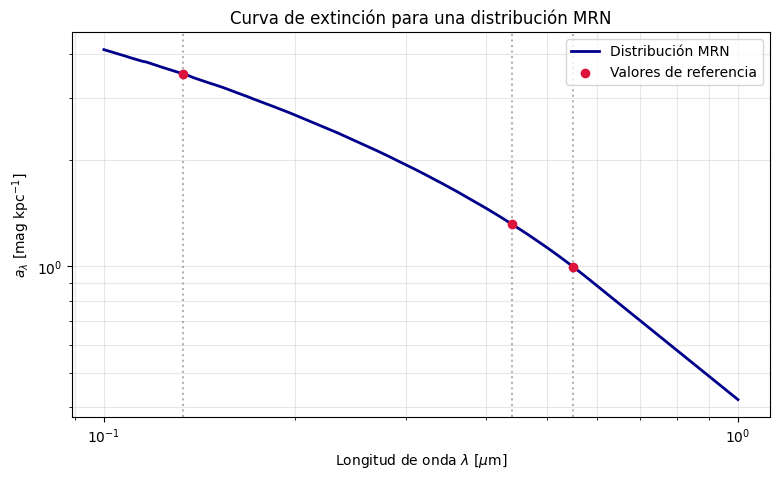

In [24]:
# Rango espectral en micrómetros
longitudes = np.logspace(
    np.log10(0.1),
    np.log10(1.0),
    150
)

extincion = np.array([
    coeficiente_extincion(lam, a_min_opt, a_max_opt)
    for lam in longitudes
])

plt.figure(figsize=(9, 5))

plt.plot(
    longitudes,
    extincion,
    color="darkblue",
    linewidth=2,
    label="Distribución MRN"
)

# Valores de referencia
plt.scatter(
    [lambda_B, lambda_V, lambda_O_um],
    [a_B_opt, a_V_opt, a_O_opt],
    color="crimson",
    zorder=5,
    label="Valores de referencia"
)

plt.axvline(lambda_B, color="gray", ls=":", alpha=0.6)
plt.axvline(lambda_V, color="gray", ls=":", alpha=0.6)
plt.axvline(lambda_O_um, color="gray", ls=":", alpha=0.6)

plt.xscale("log")
plt.yscale("log")

plt.xlabel(r"Longitud de onda $\lambda$ [$\mu$m]")
plt.ylabel(r"$a_\lambda$ [mag kpc$^{-1}$]")
plt.title("Curva de extinción para una distribución MRN")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

## Declaración de uso ético de IA
